In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("../data/raw/oedb_electrolytes_v2026_05_11.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
for i, col in enumerate(df.columns):
    print(i, col)

Dataset shape: (5616, 20)

First 5 rows:


,ID,exp-ID,Cation,Anion,Solvent,Concentration (mol/kg),Ionic Conductivity (mS/cm),Viscosity (mPa·s),Cation's Diffusivity (m²/s),Anion's Diffusivity (m²/s),Solvent's Diffusivity (m²/s),Coordination (Cation←Anion),Coordination (Cation ← Solvent),Density (g/cm³),Anion SMILES,Solvent SMILES,Anion PubChem CID,Solvent PubChem CID,x,y
0,1,NaN,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,2.510000e-09,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.781920,-21.211819
1,2,NaN,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,2.110000e-09,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.421020,-20.695742
2,3,NaN,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,1.830000e-09,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.876976,-19.905375
3,4,NaN,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,1.470000e-09,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.369880,-19.195618
4,5,NaN,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,1.200000e-09,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-58.683660,-18.369247



Column names:
0 ID
1 exp-ID
2 Cation
3 Anion
4 Solvent
5 Concentration (mol/kg)
6 Ionic Conductivity (mS/cm)
7 Viscosity (mPa·s)
8 Cation's Diffusivity (m²/s)
9 Anion's Diffusivity (m²/s)
10 Solvent's Diffusivity (m²/s)
11 Coordination (Cation←Anion)
12 Coordination (Cation ← Solvent)
13 Density (g/cm³)
14 Anion SMILES
15 Solvent SMILES
16 Anion PubChem CID
17 Solvent PubChem CID
18 x
19 y


In [2]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5616 entries, 0 to 5615
Data columns (total 20 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   ID                               5616 non-null   int64  
 1   exp-ID                           400 non-null    object 
 2   Cation                           5616 non-null   object 
 3   Anion                            5616 non-null   object 
 4   Solvent                          5616 non-null   object 
 5   Concentration (mol/kg)           5616 non-null   float64
 6   Ionic Conductivity (mS/cm)       5595 non-null   float64
 7   Viscosity (mPa·s)                5616 non-null   float64
 8   Cation's Diffusivity (m²/s)      5608 non-null   float64
 9   Anion's Diffusivity (m²/s)       5608 non-null   float64
 10  Solvent's Diffusivity (m²/s)     5616 non-null   float64
 11  Coordination (Cation←Anion)      5616 non-null   float64
 12 

In [3]:
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]

print("Columns with missing values:")
display(missing)

Columns with missing values:


exp-ID                         5216
Ionic Conductivity (mS/cm)       21
Cation's Diffusivity (m²/s)       8
Anion's Diffusivity (m²/s)        8
dtype: int64

In [4]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Number of numeric columns:", len(numeric_cols))
print(numeric_cols)

display(df[numeric_cols].describe().T)

Number of numeric columns: 14
['ID', 'Concentration (mol/kg)', 'Ionic Conductivity (mS/cm)', 'Viscosity (mPa·s)', "Cation's Diffusivity (m²/s)", "Anion's Diffusivity (m²/s)", "Solvent's Diffusivity (m²/s)", 'Coordination (Cation←Anion)', 'Coordination (Cation ← Solvent)', 'Density (g/cm³)', 'Anion PubChem CID', 'Solvent PubChem CID', 'x', 'y']


,count,mean,std,min,25%,50%,75%,max
ID,5616.0,2.808500e+03,1.621344e+03,1.000000e+00,1.404750e+03,2.808500e+03,4.212250e+03,5.616000e+03
Concentration (mol/kg),5616.0,2.250000e+00,1.145746e+00,5.000000e-01,1.375000e+00,2.250000e+00,3.125000e+00,4.000000e+00
Ionic Conductivity (mS/cm),5595.0,6.135086e+00,1.275039e+01,1.257100e-04,4.047813e-01,1.641149e+00,5.078750e+00,1.271093e+02
Viscosity (mPa·s),5616.0,1.667124e+01,3.388327e+01,1.624182e-01,2.763585e+00,7.341337e+00,1.710214e+01,5.149166e+02
Cation's Diffusivity (m²/s),5608.0,1.471195e-10,2.604107e-10,3.780000e-14,1.210000e-11,4.855000e-11,1.460000e-10,1.870000e-09
Anion's Diffusivity (m²/s),5608.0,1.528284e-10,2.718655e-10,4.920000e-14,1.260000e-11,5.260000e-11,1.560000e-10,2.430000e-09
Solvent's Diffusivity (m²/s),5616.0,4.202526e-10,6.402026e-10,4.320000e-14,3.247500e-11,1.515000e-10,5.080000e-10,4.370000e-09
Coordination (Cation←Anion),5616.0,2.789735e+00,2.207214e+00,1.086960e-04,1.312802e+00,2.310508e+00,3.622175e+00,1.379831e+01
Coordination (Cation ← Solvent),5616.0,5.476714e+00,3.603456e+00,2.323620e-01,3.115989e+00,4.511095e+00,6.854154e+00,4.568165e+01
Density (g/cm³),5616.0,1.217192e+00,1.812000e-01,7.612277e-01,1.105142e+00,1.208001e+00,1.331979e+00,1.781734e+00


In [5]:
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("Number of categorical columns:", len(cat_cols))
print(cat_cols)

for col in cat_cols:
    print("\n" + "="*80)
    print("Column:", col)
    print(df[col].value_counts(dropna=False).head(15))

Number of categorical columns: 6
['exp-ID', 'Cation', 'Anion', 'Solvent', 'Anion SMILES', 'Solvent SMILES']

Column: exp-ID
exp-ID
NaN         5216
exp-3          1
exp-1282       1
exp-1231       1
exp-1233       1
exp-1235       1
exp-1237       1
exp-1239       1
exp-1241       1
exp-1243       1
exp-1245       1
exp-1247       1
exp-1270       1
exp-1272       1
exp-1274       1
Name: count, dtype: int64

Column: Cation
Cation
K     1872
Li    1872
Na    1872
Name: count, dtype: int64

Column: Anion
Anion
BETI    624
BF4     624
ClO4    624
DFOB    624
FSI     624
OTf     624
PF6     624
TFA     624
TFSI    624
Name: count, dtype: int64

Column: Solvent
Solvent
AN      216
Ac2O    216
Ac      216
BC      216
DEC     216
DMC     216
DMI     216
DMSO    216
EA      216
EB      216
EC      216
EMC     216
EP      216
FAN     216
FEA     216
Name: count, dtype: int64

Column: Anion SMILES
Anion SMILES
C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F)(F)(F)F    624
[B-](F)(F)(F)F         

In [6]:
df_clean = df.rename(columns={
    "ID": "id",
    "exp-ID": "exp_id",
    "Cation": "cation",
    "Anion": "anion",
    "Solvent": "solvent",
    "Concentration (mol/kg)": "concentration_mol_kg",
    "Ionic Conductivity (mS/cm)": "ionic_conductivity_ms_cm",
    "Viscosity (mPa·s)": "viscosity_mpa_s",
    "Cation's Diffusivity (m²/s)": "cation_diffusivity_m2_s",
    "Anion's Diffusivity (m²/s)": "anion_diffusivity_m2_s",
    "Solvent's Diffusivity (m²/s)": "solvent_diffusivity_m2_s",
    "Coordination (Cation←Anion)": "coordination_cation_anion",
    "Coordination (Cation ← Solvent)": "coordination_cation_solvent",
    "Density (g/cm³)": "density_g_cm3",
    "Anion SMILES": "anion_smiles",
    "Solvent SMILES": "solvent_smiles",
    "Anion PubChem CID": "anion_pubchem_cid",
    "Solvent PubChem CID": "solvent_pubchem_cid",
    "x": "tsne_x",
    "y": "tsne_y"
})

print(df_clean.columns.tolist())
display(df_clean.head())

['id', 'exp_id', 'cation', 'anion', 'solvent', 'concentration_mol_kg', 'ionic_conductivity_ms_cm', 'viscosity_mpa_s', 'cation_diffusivity_m2_s', 'anion_diffusivity_m2_s', 'solvent_diffusivity_m2_s', 'coordination_cation_anion', 'coordination_cation_solvent', 'density_g_cm3', 'anion_smiles', 'solvent_smiles', 'anion_pubchem_cid', 'solvent_pubchem_cid', 'tsne_x', 'tsne_y']


,id,exp_id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,viscosity_mpa_s,cation_diffusivity_m2_s,anion_diffusivity_m2_s,solvent_diffusivity_m2_s,coordination_cation_anion,coordination_cation_solvent,density_g_cm3,anion_smiles,solvent_smiles,anion_pubchem_cid,solvent_pubchem_cid,tsne_x,tsne_y
0,1,NaN,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,2.510000e-09,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.781920,-21.211819
1,2,NaN,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,2.110000e-09,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.421020,-20.695742
2,3,NaN,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,1.830000e-09,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.876976,-19.905375
3,4,NaN,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,1.470000e-09,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.369880,-19.195618
4,5,NaN,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,1.200000e-09,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-58.683660,-18.369247


In [7]:
selected_cols = [
    "id",
    "cation",
    "anion",
    "solvent",
    "concentration_mol_kg",
    "ionic_conductivity_ms_cm",
    "viscosity_mpa_s",
    "cation_diffusivity_m2_s",
    "anion_diffusivity_m2_s",
    "solvent_diffusivity_m2_s",
    "coordination_cation_anion",
    "coordination_cation_solvent",
    "density_g_cm3",
    "anion_smiles",
    "solvent_smiles"
]

data = df_clean[selected_cols].copy()

print("Selected dataset shape:", data.shape)
display(data.head())

Selected dataset shape: (5616, 15)


,id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,viscosity_mpa_s,cation_diffusivity_m2_s,anion_diffusivity_m2_s,solvent_diffusivity_m2_s,coordination_cation_anion,coordination_cation_solvent,density_g_cm3,anion_smiles,solvent_smiles
0,1,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,2.510000e-09,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N
1,2,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,2.110000e-09,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N
2,3,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,1.830000e-09,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N
3,4,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,1.470000e-09,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N
4,5,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,1.200000e-09,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N


In [8]:
missing_selected = data.isnull().sum().sort_values(ascending=False)

print("Missing values in selected columns:")
display(missing_selected)

Missing values in selected columns:


ionic_conductivity_ms_cm       21
anion_diffusivity_m2_s          8
cation_diffusivity_m2_s         8
anion                           0
solvent                         0
cation                          0
id                              0
viscosity_mpa_s                 0
concentration_mol_kg            0
solvent_diffusivity_m2_s        0
coordination_cation_anion       0
coordination_cation_solvent     0
density_g_cm3                   0
anion_smiles                    0
solvent_smiles                  0
dtype: int64

In [9]:
print("Unique cations:", data["cation"].nunique())
print(data["cation"].value_counts())

print("\nUnique anions:", data["anion"].nunique())
print(data["anion"].value_counts())

print("\nUnique solvents:", data["solvent"].nunique())
print(data["solvent"].value_counts().head(20))

print("\nUnique concentrations:", sorted(data["concentration_mol_kg"].unique()))

Unique cations: 3
cation
K     1872
Li    1872
Na    1872
Name: count, dtype: int64

Unique anions: 9
anion
BETI    624
BF4     624
ClO4    624
DFOB    624
FSI     624
OTf     624
PF6     624
TFA     624
TFSI    624
Name: count, dtype: int64

Unique solvents: 26
solvent
AN      216
Ac2O    216
Ac      216
BC      216
DEC     216
DMC     216
DMI     216
DMSO    216
EA      216
EB      216
EC      216
EMC     216
EP      216
FAN     216
FEA     216
FEC     216
FEMC    216
GBL     216
GN      216
MA      216
Name: count, dtype: int64

Unique concentrations: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0)]


In [10]:
from rdkit import Chem

def is_valid_smiles(smiles):
    if pd.isna(smiles):
        return False
    mol = Chem.MolFromSmiles(str(smiles))
    return mol is not None

data["valid_anion_smiles"] = data["anion_smiles"].apply(is_valid_smiles)
data["valid_solvent_smiles"] = data["solvent_smiles"].apply(is_valid_smiles)

print("Valid anion SMILES:")
print(data["valid_anion_smiles"].value_counts())

print("\nValid solvent SMILES:")
print(data["valid_solvent_smiles"].value_counts())

invalid_rows = data[(~data["valid_anion_smiles"]) | (~data["valid_solvent_smiles"])]
print("\nInvalid SMILES rows:", invalid_rows.shape[0])
display(invalid_rows.head())

Valid anion SMILES:
valid_anion_smiles
True    5616
Name: count, dtype: int64

Valid solvent SMILES:
valid_solvent_smiles
True    5616
Name: count, dtype: int64

Invalid SMILES rows: 0


,id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,viscosity_mpa_s,cation_diffusivity_m2_s,anion_diffusivity_m2_s,solvent_diffusivity_m2_s,coordination_cation_anion,coordination_cation_solvent,density_g_cm3,anion_smiles,solvent_smiles,valid_anion_smiles,valid_solvent_smiles


In [11]:
model_data = data[
    data["ionic_conductivity_ms_cm"].notna()
    & data["anion_smiles"].notna()
    & data["solvent_smiles"].notna()
    & data["valid_anion_smiles"]
    & data["valid_solvent_smiles"]
].copy()

print("Model dataset shape:", model_data.shape)
display(model_data.head())

Model dataset shape: (5595, 17)


,id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,viscosity_mpa_s,cation_diffusivity_m2_s,anion_diffusivity_m2_s,solvent_diffusivity_m2_s,coordination_cation_anion,coordination_cation_solvent,density_g_cm3,anion_smiles,solvent_smiles,valid_anion_smiles,valid_solvent_smiles
0,1,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,2.510000e-09,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,True,True
1,2,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,2.110000e-09,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,True,True
2,3,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,1.830000e-09,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,True,True
3,4,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,1.470000e-09,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,True,True
4,5,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,1.200000e-09,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,True,True


In [12]:
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def smiles_to_morgan_array(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")
    
    fp = morgan_generator.GetFingerprint(mol)
    arr = np.zeros((1024,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

# test fingerprint
test_fp = smiles_to_morgan_array(model_data["solvent_smiles"].iloc[0])

print("Fingerprint length:", len(test_fp))
print("Active bits:", test_fp.sum())
print("First 20 bits:", test_fp[:20])

Fingerprint length: 1024
Active bits: 6
First 20 bits: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [13]:
anion_fps = np.vstack(model_data["anion_smiles"].apply(smiles_to_morgan_array).values)
solvent_fps = np.vstack(model_data["solvent_smiles"].apply(smiles_to_morgan_array).values)

print("Anion fingerprint matrix:", anion_fps.shape)
print("Solvent fingerprint matrix:", solvent_fps.shape)

cation_onehot = pd.get_dummies(model_data["cation"], prefix="cation").astype(int)
concentration = model_data[["concentration_mol_kg"]].reset_index(drop=True)

X = np.hstack([
    anion_fps,
    solvent_fps,
    cation_onehot.reset_index(drop=True).values,
    concentration.values
])

y = model_data["ionic_conductivity_ms_cm"].values

print("Final feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Cation one-hot columns:", cation_onehot.columns.tolist())

Anion fingerprint matrix: (5595, 1024)
Solvent fingerprint matrix: (5595, 1024)
Final feature matrix shape: (5595, 2052)
Target shape: (5595,)
Cation one-hot columns: ['cation_K', 'cation_Li', 'cation_Na']


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    max_depth=None
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
spearman = spearmanr(y_test, y_pred).correlation

metrics = {
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2,
    "Spearman": spearman
}

metrics

{'MAE': 2.096475067116374,
 'RMSE': np.float64(5.8466669807997524),
 'R2': 0.7684223666071344,
 'Spearman': np.float64(0.9566629486231706)}

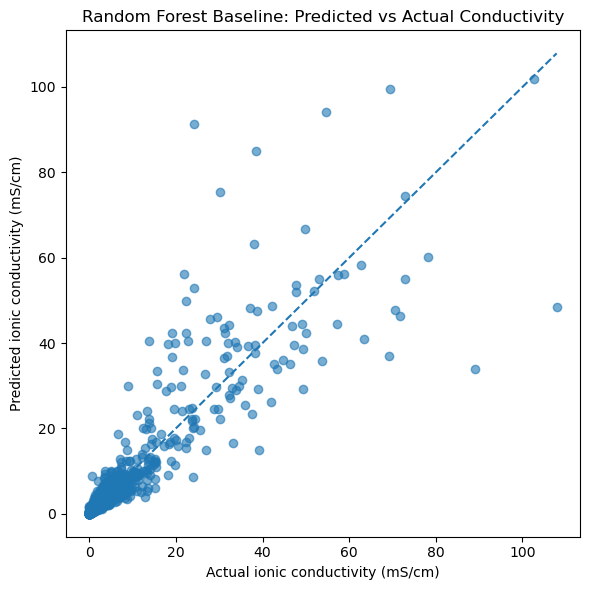

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual ionic conductivity (mS/cm)")
plt.ylabel("Predicted ionic conductivity (mS/cm)")
plt.title("Random Forest Baseline: Predicted vs Actual Conductivity")
plt.tight_layout()

plt.savefig("../outputs/figures/predicted_vs_actual_conductivity.png", dpi=300)
plt.show()

In [16]:
metrics_df = pd.DataFrame([metrics])
metrics_df.to_csv("../outputs/metrics/random_forest_conductivity_metrics.csv", index=False)

display(metrics_df)

,MAE,RMSE,R2,Spearman
0,2.096475,5.846667,0.768422,0.956663


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

# Keep indices so that predictions can be connected back to the original electrolyte records
indices = np.arange(len(model_data))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

metrics = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2": r2_score(y_test, y_pred),
    "Spearman": spearmanr(y_test, y_pred).correlation
}

metrics_df = pd.DataFrame([metrics])
display(metrics_df)

# Create prediction-level result table
prediction_results = model_data.iloc[test_idx][[
    "id",
    "cation",
    "anion",
    "solvent",
    "concentration_mol_kg",
    "ionic_conductivity_ms_cm"
]].copy()

prediction_results["predicted_conductivity_ms_cm"] = y_pred
prediction_results["absolute_error"] = np.abs(
    prediction_results["ionic_conductivity_ms_cm"] - prediction_results["predicted_conductivity_ms_cm"]
)

display(prediction_results.head())

,MAE,RMSE,R2,Spearman
0,2.096475,5.846667,0.768422,0.956663


,id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,predicted_conductivity_ms_cm,absolute_error
2452,2453,Li,ClO4,MB,2.5,0.239354,0.672763,0.433409
2177,2178,Li,BF4,EP,1.0,1.441737,1.667062,0.225324
3503,3504,Li,TFA,MP,4.0,0.246691,0.537265,0.290574
3056,3057,Li,OTf,GN,0.5,0.150622,0.221830,0.071208
298,299,K,BF4,EMC,1.5,0.021774,0.276885,0.255111


In [18]:
prediction_results.to_csv(
    "../outputs/metrics/random_forest_conductivity_predictions.csv",
    index=False
)

metrics_df.to_csv(
    "../outputs/metrics/random_forest_conductivity_metrics.csv",
    index=False
)

print("Saved prediction results and metrics.")

Saved prediction results and metrics.


In [19]:
def group_error_summary(df, group_col):
    summary = (
        df.groupby(group_col)
        .agg(
            count=("absolute_error", "count"),
            mean_abs_error=("absolute_error", "mean"),
            median_abs_error=("absolute_error", "median"),
            max_abs_error=("absolute_error", "max")
        )
        .sort_values("mean_abs_error", ascending=False)
    )
    return summary

cation_error = group_error_summary(prediction_results, "cation")
anion_error = group_error_summary(prediction_results, "anion")
solvent_error = group_error_summary(prediction_results, "solvent")
concentration_error = group_error_summary(prediction_results, "concentration_mol_kg")

print("Error by cation:")
display(cation_error)

print("Error by anion:")
display(anion_error)

print("Error by solvent:")
display(solvent_error.head(15))

print("Error by concentration:")
display(concentration_error)

Error by cation:


,count,mean_abs_error,median_abs_error,max_abs_error
cation,,,,
K,401,2.687905,0.745644,67.141694
Li,363,2.012192,0.327066,55.094602
Na,355,1.514592,0.474254,28.686415


Error by anion:


,count,mean_abs_error,median_abs_error,max_abs_error
anion,,,,
PF6,113,3.630273,0.744523,45.238406
TFSI,114,3.062505,0.526807,67.141694
ClO4,117,2.392218,0.328253,59.478859
FSI,124,2.289128,0.792733,28.686415
BETI,126,2.254816,0.529930,27.500249
BF4,137,1.742244,0.698955,21.008917
DFOB,135,1.653631,0.422793,24.273665
OTf,126,1.515616,0.335658,16.722735
TFA,127,0.676109,0.254803,8.816027


Error by solvent:


,count,mean_abs_error,median_abs_error,max_abs_error
solvent,,,,
AN,40,14.315511,8.861711,67.141694
Ac,43,11.573004,8.403380,45.238406
FAN,45,6.662113,3.300122,34.255468
DMSO,46,4.861521,3.448115,24.273665
Ac2O,50,2.503745,2.057632,8.411546
GBL,39,1.732073,1.175714,9.186753
EC,53,1.312248,0.922909,6.741526
MP,38,1.235446,0.825870,5.771928
FEC,32,1.217187,0.949777,5.612604


Error by concentration:


,count,mean_abs_error,median_abs_error,max_abs_error
concentration_mol_kg,,,,
1.5,132,2.487217,0.616058,59.478859
3.0,162,2.418848,0.425523,67.141694
2.5,132,2.390687,0.707385,46.547864
0.5,145,2.199696,0.626724,45.238406
1.0,144,2.129373,0.479230,39.339296
3.5,136,1.841429,0.351281,28.686415
2.0,135,1.826441,0.404175,34.255468
4.0,133,1.410748,0.327066,22.897883


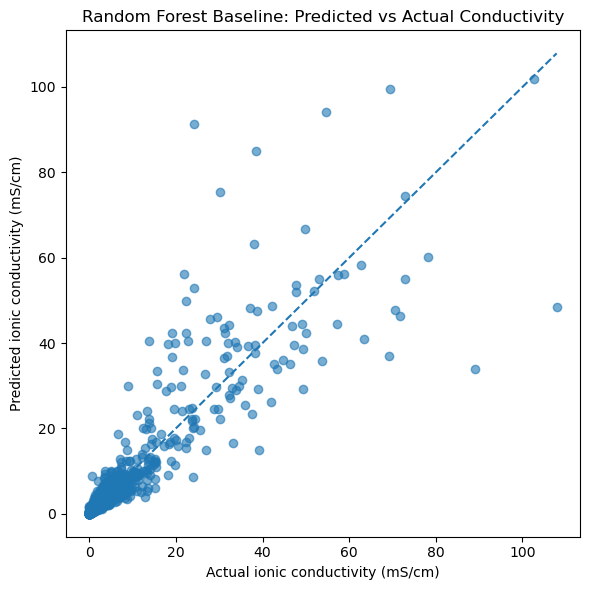

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(
    prediction_results["ionic_conductivity_ms_cm"],
    prediction_results["predicted_conductivity_ms_cm"],
    alpha=0.6
)

min_val = min(
    prediction_results["ionic_conductivity_ms_cm"].min(),
    prediction_results["predicted_conductivity_ms_cm"].min()
)

max_val = max(
    prediction_results["ionic_conductivity_ms_cm"].max(),
    prediction_results["predicted_conductivity_ms_cm"].max()
)

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual ionic conductivity (mS/cm)")
plt.ylabel("Predicted ionic conductivity (mS/cm)")
plt.title("Random Forest Baseline: Predicted vs Actual Conductivity")
plt.tight_layout()

plt.savefig("../outputs/figures/predicted_vs_actual_conductivity.png", dpi=300)
plt.show()

In [21]:
from sklearn.model_selection import GroupShuffleSplit

groups = model_data["solvent"].values

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

for train_idx_group, test_idx_group in gss.split(X, y, groups=groups):
    X_train_group, X_test_group = X[train_idx_group], X[test_idx_group]
    y_train_group, y_test_group = y[train_idx_group], y[test_idx_group]

    heldout_solvents = sorted(model_data.iloc[test_idx_group]["solvent"].unique())
    print("Held-out solvents:", heldout_solvents)

    rf_group_model = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    rf_group_model.fit(X_train_group, y_train_group)
    y_pred_group = rf_group_model.predict(X_test_group)

    solvent_holdout_metrics = {
        "Validation": "Solvent-held-out split",
        "MAE": mean_absolute_error(y_test_group, y_pred_group),
        "RMSE": np.sqrt(mean_squared_error(y_test_group, y_pred_group)),
        "R2": r2_score(y_test_group, y_pred_group),
        "Spearman": spearmanr(y_test_group, y_pred_group).correlation
    }

solvent_holdout_metrics_df = pd.DataFrame([solvent_holdout_metrics])
display(solvent_holdout_metrics_df)

Held-out solvents: ['AN', 'EA', 'EB', 'EMC', 'FEMC', 'TEP']


,Validation,MAE,RMSE,R2,Spearman
0,Solvent-held-out split,7.549065,18.521617,-0.132344,0.243569


In [22]:
random_split_metrics = metrics_df.copy()
random_split_metrics.insert(0, "Validation", "Random split")

comparison_metrics = pd.concat(
    [random_split_metrics, solvent_holdout_metrics_df],
    ignore_index=True
)

display(comparison_metrics)

comparison_metrics.to_csv(
    "../outputs/metrics/validation_comparison_metrics.csv",
    index=False
)

,Validation,MAE,RMSE,R2,Spearman
0,Random split,2.096475,5.846667,0.768422,0.956663
1,Solvent-held-out split,7.549065,18.521617,-0.132344,0.243569
